In [9]:
import numpy as np 
import matplotlib.pyplot as plt 
from scipy import signal

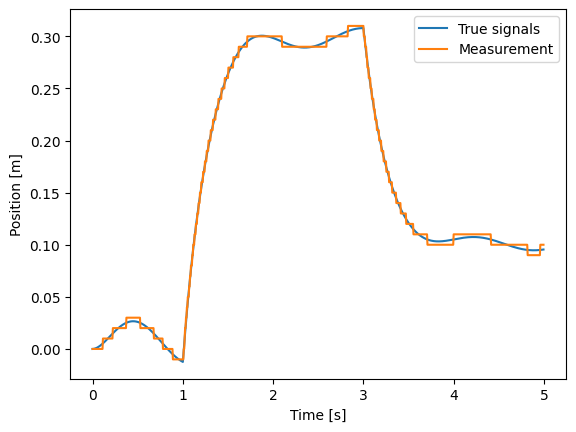

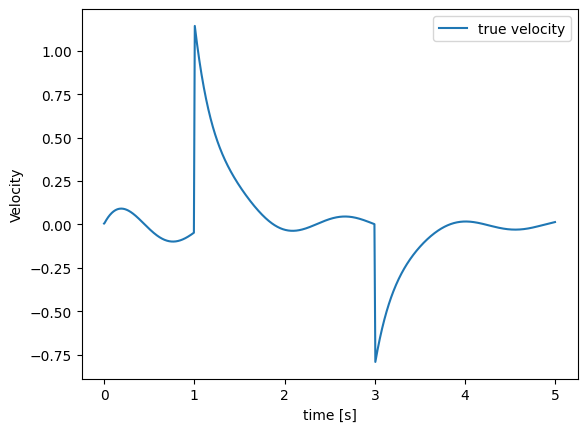

In [10]:
Ts = 0.005
t = np.arange(0,5,Ts)

xr = np.zeros(len(t))

xr[t>1] = 0.3
xr[t>3] = 0.1

xr += 0.05*np.sin(t*5) * 1/(t + 1)

alpha = 0.98
x = signal.lfilter([(1-alpha),0],[1, -alpha],xr)

xs = np.round(x,2)

#plt.plot(t,xr)
plt.plot(t,x,label='True signals')
plt.plot(t,xs, label='Measurement')
plt.legend()
plt.xlabel('Time [s]')
plt.ylabel("Position [m]")

v = np.gradient(x)*1/Ts

vs = xs[1:] - xs[:-1]

vs = np.r_[vs,[vs[-1]]] * 1/Ts

plt.figure()
plt.plot(t,v,label="true velocity")
#plt.plot(t,vs,label="Estimated from discrete")
plt.xlabel("time [s]")
plt.ylabel("Velocity")
plt.legend()

In [11]:
import control as ctrl 

# Constant velocity model
# x = [pos; vel]
A = np.array([[1, Ts] ,
              [0, 1]])

# Meas pos
C = np.array([[1, 0]])


G = np.eye(2)

Q = np.diag([1e-5,100])
R = 100.0

L, _, E = ctrl.dlqe(A,G,C,Q,R)

print(L)


[[0.09993797]
 [0.95121928]]


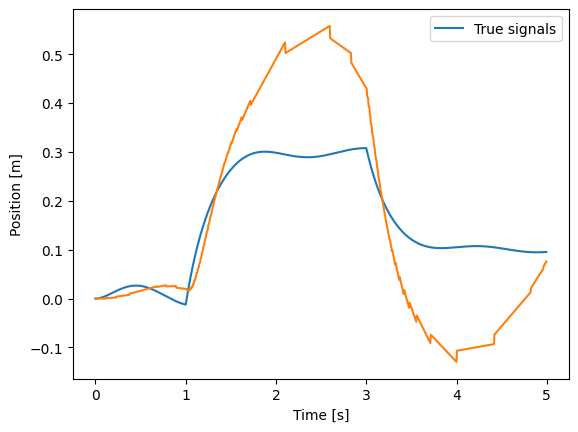

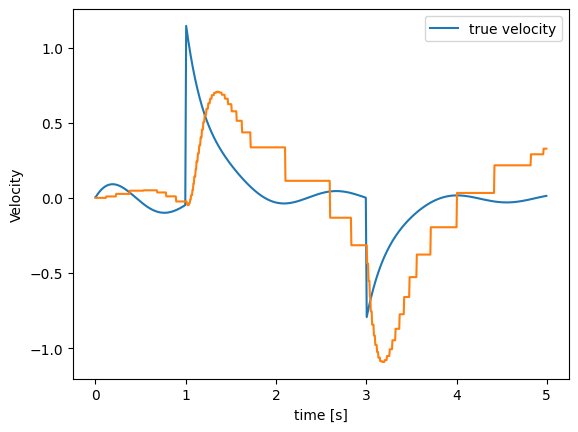

In [12]:

Xs = []

NEW_MEAS = []

X = np.array([0,0]).reshape(2,1)

old_xs = 0.0


for i in range(len(xs)):

    xsi = xs[i]

    new_xs = abs(xsi - old_xs) > 0.0001
    old_xs = xsi

    XSp = A@X

    if new_xs or i == 0:
        NEW_MEAS.append(1)
        XSp = (A - L@C) @ X + L*xsi
    else:
        NEW_MEAS.append(0)

    Xs.append(X)
    X = XSp 

Xs = np.array(Xs).squeeze()



plt.plot(t,x,label='True signals')
#plt.plot(t,xs, label='Measurement')
plt.plot(t,Xs[:,0])
plt.legend()
plt.xlabel('Time [s]')
plt.ylabel("Position [m]")



plt.figure()
plt.plot(t,v,label="true velocity")
#plt.plot(t,vs,label="Estimated from discrete")
plt.plot(t,Xs[:,1])
plt.xlabel("time [s]")
plt.ylabel("Velocity")
plt.legend()



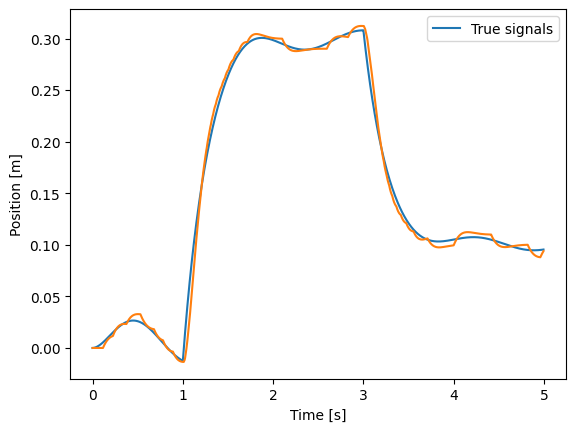

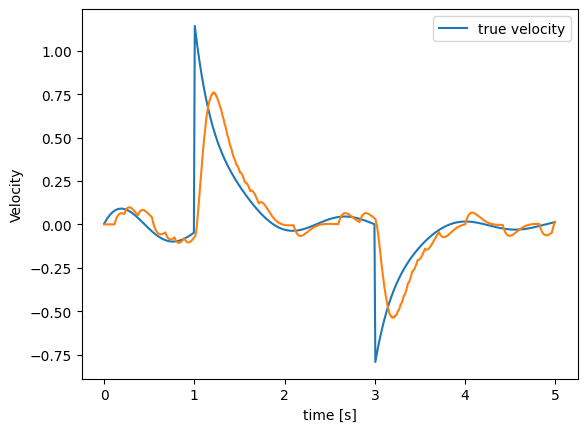

In [13]:

Xs = []

NEW_MEAS = []

X = np.array([0,0]).reshape(2,1)

old_xs = 0.0


for i in range(len(xs)):

    xsi = xs[i]

    new_xs = abs(xsi - old_xs) > 0.0001
    old_xs = xsi

    XSp = (A - L@C) @ X + L*xsi


    Xs.append(X)
    X = XSp 

Xs = np.array(Xs).squeeze()



plt.plot(t,x,label='True signals')
#plt.plot(t,xs, label='Measurement')
plt.plot(t,Xs[:,0])
plt.legend()
plt.xlabel('Time [s]')
plt.ylabel("Position [m]")



plt.figure()
plt.plot(t,v,label="true velocity")
#plt.plot(t,vs,label="Estimated from discrete")
plt.plot(t,Xs[:,1])
plt.xlabel("time [s]")
plt.ylabel("Velocity")
plt.legend()



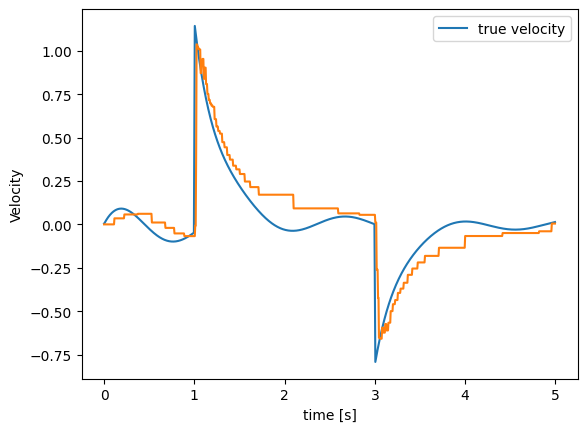

In [14]:


VES = []

old_xs = 0.0
last_ti = 0.0

max_delta_t = 100*Ts



ALPHA = 0.6
v_est = 0.0


for i in range(len(xs)):

    xsi = xs[i]

    new_xs = abs(xsi - old_xs) > 0.0001
    
    if new_xs:

        delta_t = i*Ts - last_ti

        delta_t = np.clip(delta_t,Ts,max_delta_t)

        last_ti = i*Ts
        v_est_raw = (xsi - old_xs)/delta_t
        v_est = ALPHA*v_est + (1-ALPHA)*v_est_raw



    old_xs = xsi

    VES.append(v_est)

VES = np.array(VES)

plt.figure()
plt.plot(t,v,label="true velocity")
plt.plot(t,VES)
plt.xlabel("time [s]")
plt.ylabel("Velocity")
plt.legend()



## Kalman filter with quantization noise as `R`

Instead of branching on "did the measurement change", treat quantization as additive uniform
noise with variance `q**2/12` and just run predict+update every step with that fixed `R`.
When the quantized value stays flat, the filter naturally infers velocity ~= 0; when it jumps,
the filter pulls the state toward the new value at a rate set by `Q`/`R`.

L = [0.10459188 1.03958031]


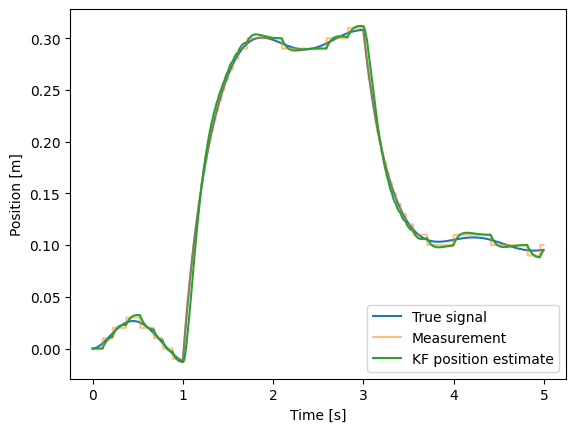

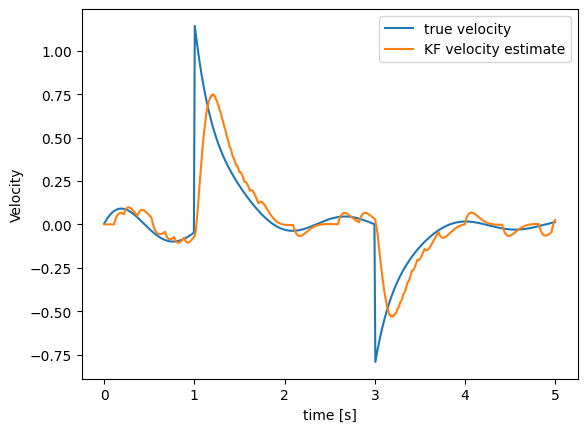

In [15]:
q_step = 0.01  # quantization step used above (np.round(x,2))

R_quant = q_step**2 / 12

Q_quant = np.diag([1e-15, 1e-5])  # process noise: small pos noise, low trust in sudden velocity jumps

L_quant, _, _ = ctrl.dlqe(A, G, C, Q_quant, R_quant)

print("L =", L_quant.ravel())

Xq = np.array([0.0, 0.0]).reshape(2, 1)
Xqs = []

for i in range(len(xs)):
    Xq = A @ Xq
    Xq = Xq + L_quant * (xs[i] - C @ Xq)
    Xqs.append(Xq)

Xqs = np.array(Xqs).squeeze()

plt.plot(t, x, label='True signal')
plt.plot(t, xs, label='Measurement', alpha=0.5)
plt.plot(t, Xqs[:, 0], label='KF position estimate')
plt.legend()
plt.xlabel('Time [s]')
plt.ylabel("Position [m]")

plt.figure()
plt.plot(t, v, label="true velocity")
plt.plot(t, Xqs[:, 1], label="KF velocity estimate")
plt.xlabel("time [s]")
plt.ylabel("Velocity")
plt.legend()

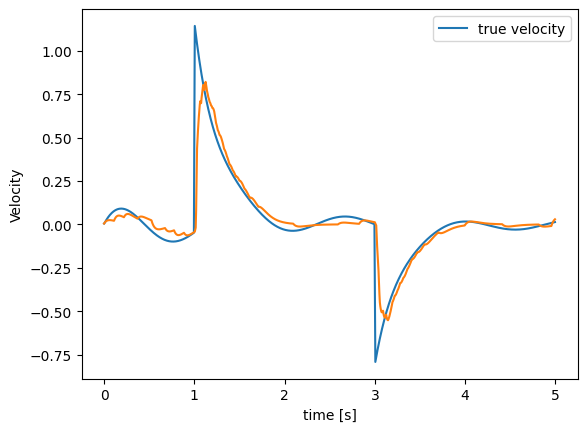

In [ ]:

# TIME Y DELTA ESTIMATOR

VES = []

old_xs = 0.0
last_ti = 0.0

max_delta_t = 100*Ts



ALPHA = 0.9
v_est = 0.0


for i in range(len(xs)):

    xsi = xs[i]

    new_xs = abs(xsi - old_xs) > 0.001
    
    if new_xs :

        delta_t = i*Ts - last_ti

        delta_t = np.clip(delta_t,Ts,max_delta_t)

        last_ti = i*Ts
        v_est_raw = (xsi - old_xs)/delta_t
    else:
        v_est_raw = v_est_raw*0.95


    v_est = ALPHA*v_est + (1-ALPHA)*v_est_raw

    old_xs = xsi

    VES.append(v_est)

VES = np.array(VES)

plt.figure()
plt.plot(t,v,label="true velocity")
plt.plot(t,VES)
plt.xlabel("time [s]")
plt.ylabel("Velocity")
plt.legend()



Polynomial degree: 2
Window length: 9 position changes
Used 67 of 1000 samples for fitting
Finite estimates: True


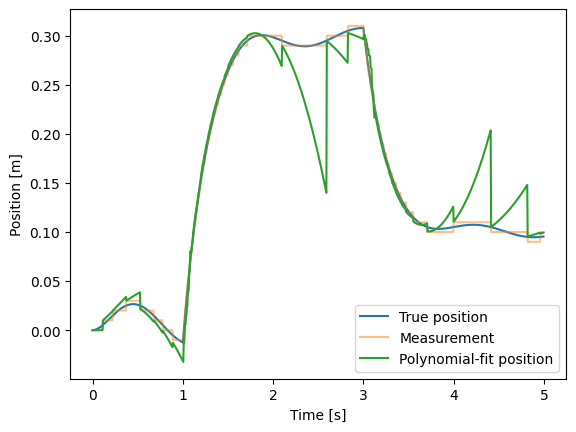

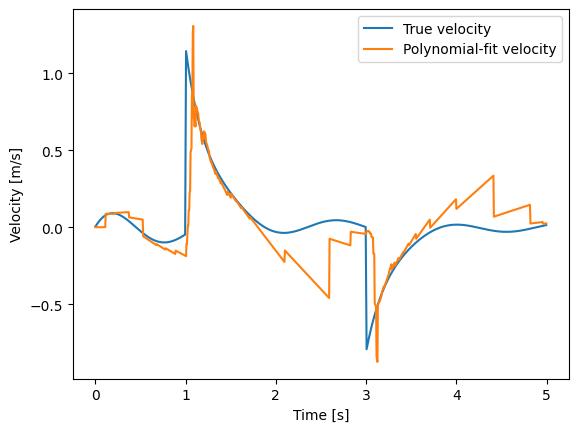

In [36]:
# Causal moving-window polynomial estimator using only position changes
POLY_WINDOW = 9
POLY_DEGREE = 2

change_indices = np.flatnonzero(np.r_[True, np.diff(xs) != 0])
poly_position = np.empty(len(xs))
poly_velocity = np.empty(len(xs))
last_position = xs[0]
last_velocity = 0.0

for i in range(len(xs)):
    fit_indices = change_indices[change_indices <= i][-POLY_WINDOW:]
    fit_degree = min(POLY_DEGREE, len(fit_indices) - 1)

    if fit_degree >= 1:
        time_from_current = (fit_indices - i) * Ts
        coefficients = np.polyfit(time_from_current, xs[fit_indices], fit_degree)
        polynomial = np.poly1d(coefficients)
        last_position = polynomial(0.0)
        last_velocity = polynomial.deriv()(0.0)

    poly_position[i] = last_position
    poly_velocity[i] = last_velocity

print(f"Polynomial degree: {POLY_DEGREE}")
print(f"Window length: {POLY_WINDOW} position changes")
print(f"Used {len(change_indices)} of {len(xs)} samples for fitting")
print(f"Finite estimates: {np.isfinite(poly_position).all() and np.isfinite(poly_velocity).all()}")

plt.figure()
plt.plot(t, x, label="True position")
plt.plot(t, xs, label="Measurement", alpha=0.5)
plt.plot(t, poly_position, label="Polynomial-fit position")
plt.xlabel("Time [s]")
plt.ylabel("Position [m]")
plt.legend()

plt.figure()
plt.plot(t, v, label="True velocity")
plt.plot(t, poly_velocity, label="Polynomial-fit velocity")
plt.xlabel("Time [s]")
plt.ylabel("Velocity [m/s]")
plt.legend()
